# Clustering: K-Means and Hierarchical Clustering

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import load_iris
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

## Distance and similarity calculations

- **Euclidean distance** is the straight-line distance between two points.
- **Manhattan distance** is the sum of absolute coordinate differences.
- **Cosine similarity** compares the angle between two vectors and is close to 1 when their directions are similar.

In [2]:
def euclidean_distance(first, second):
    first, second = np.asarray(first), np.asarray(second)
    return np.sqrt(np.sum((first - second) ** 2))


def manhattan_distance(first, second):
    first, second = np.asarray(first), np.asarray(second)
    return np.sum(np.abs(first - second))


def cosine_similarity(first, second):
    first, second = np.asarray(first), np.asarray(second)
    denominator = np.linalg.norm(first) * np.linalg.norm(second)
    if denominator == 0:
        raise ValueError("Cosine similarity is undefined for a zero vector.")
    return np.dot(first, second) / denominator


first_vector = np.array([1, 2, 3])
second_vector = np.array([2, 4, 5])

distance_table = pd.DataFrame(
    {
        "Measure": ["Euclidean distance", "Manhattan distance", "Cosine similarity"],
        "Value": [
            euclidean_distance(first_vector, second_vector),
            manhattan_distance(first_vector, second_vector),
            cosine_similarity(first_vector, second_vector),
        ],
    }
)
distance_table.round(4)

,Measure,Value
0,Euclidean distance,3.000
1,Manhattan distance,5.000
2,Cosine similarity,0.996


In [3]:
# Load the Iris data and standardize the four measurements.
data = load_iris(as_frame=True)
X = data.data
y = data.target
X_scaled = StandardScaler().fit_transform(X)

print(f"Samples: {X_scaled.shape[0]}")
print(f"Features: {list(X.columns)}")
print(f"Classes: {list(data.target_names)}")

Samples: 150
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## K-means clustering


In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_metrics = {
    "Silhouette score": silhouette_score(X_scaled, kmeans_labels),
    "Adjusted Rand index": adjusted_rand_score(y, kmeans_labels),
    "Inertia": kmeans.inertia_,
    "Iterations": kmeans.n_iter_,
}

print(pd.Series(kmeans_metrics).round(4))
print("\nCluster centers in standardized feature space:")
pd.DataFrame(kmeans.cluster_centers_, columns=X.columns).round(3)

Silhouette score         0.4599
Adjusted Rand index      0.6201
Inertia                139.8205
Iterations               4.0000
dtype: float64

Cluster centers in standardized feature space:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.050,-0.883,0.348,0.282
1,-1.015,0.853,-1.305,-1.255
2,1.136,0.088,0.996,1.018


In [5]:
# Use the elbow curve to inspect candidate values of k.
inertias = []
silhouettes = []
k_values = range(2, 8)

for k in k_values:
    candidate = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = candidate.fit_predict(X_scaled)
    inertias.append(candidate.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

elbow_results = pd.DataFrame(
    {"k": list(k_values), "Inertia": inertias, "Silhouette": silhouettes}
).set_index("k")
elbow_results.round(4)

,Inertia,Silhouette
k,,
2,222.3617,0.5818
3,139.8205,0.4599
4,114.0925,0.3869
5,90.9275,0.3459
6,81.5444,0.3171
7,72.6311,0.3202


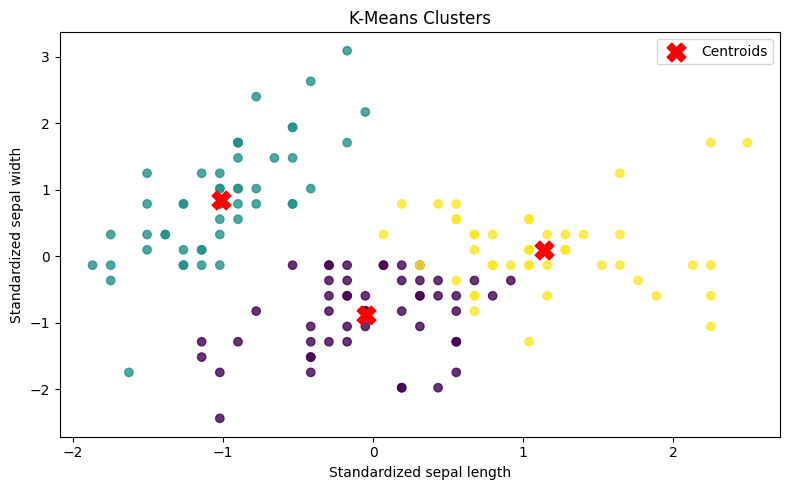

In [6]:
# Visualize K-means assignments using the first two standardized features.
plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    alpha=0.8,
)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c="red",
    marker="X",
    s=180,
    label="Centroids",
)
plt.xlabel("Standardized sepal length")
plt.ylabel("Standardized sepal width")
plt.title("K-Means Clusters")
plt.legend()
plt.tight_layout()
plt.show()

## Hierarchical clustering and linkage methods


In [7]:
linkage_methods = ["single", "complete", "average", "ward"]
hierarchical_results = []
hierarchical_labels = {}

for method in linkage_methods:
    model = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = model.fit_predict(X_scaled)
    hierarchical_labels[method] = labels
    hierarchical_results.append(
        {
            "Linkage": method,
            "Silhouette": silhouette_score(X_scaled, labels),
            "Adjusted Rand": adjusted_rand_score(y, labels),
        }
    )

hierarchical_table = pd.DataFrame(hierarchical_results).set_index("Linkage")
hierarchical_table.round(4)

,Silhouette,Adjusted Rand
Linkage,,
single,0.5046,0.5584
complete,0.4496,0.5726
average,0.4803,0.5621
ward,0.4467,0.6153


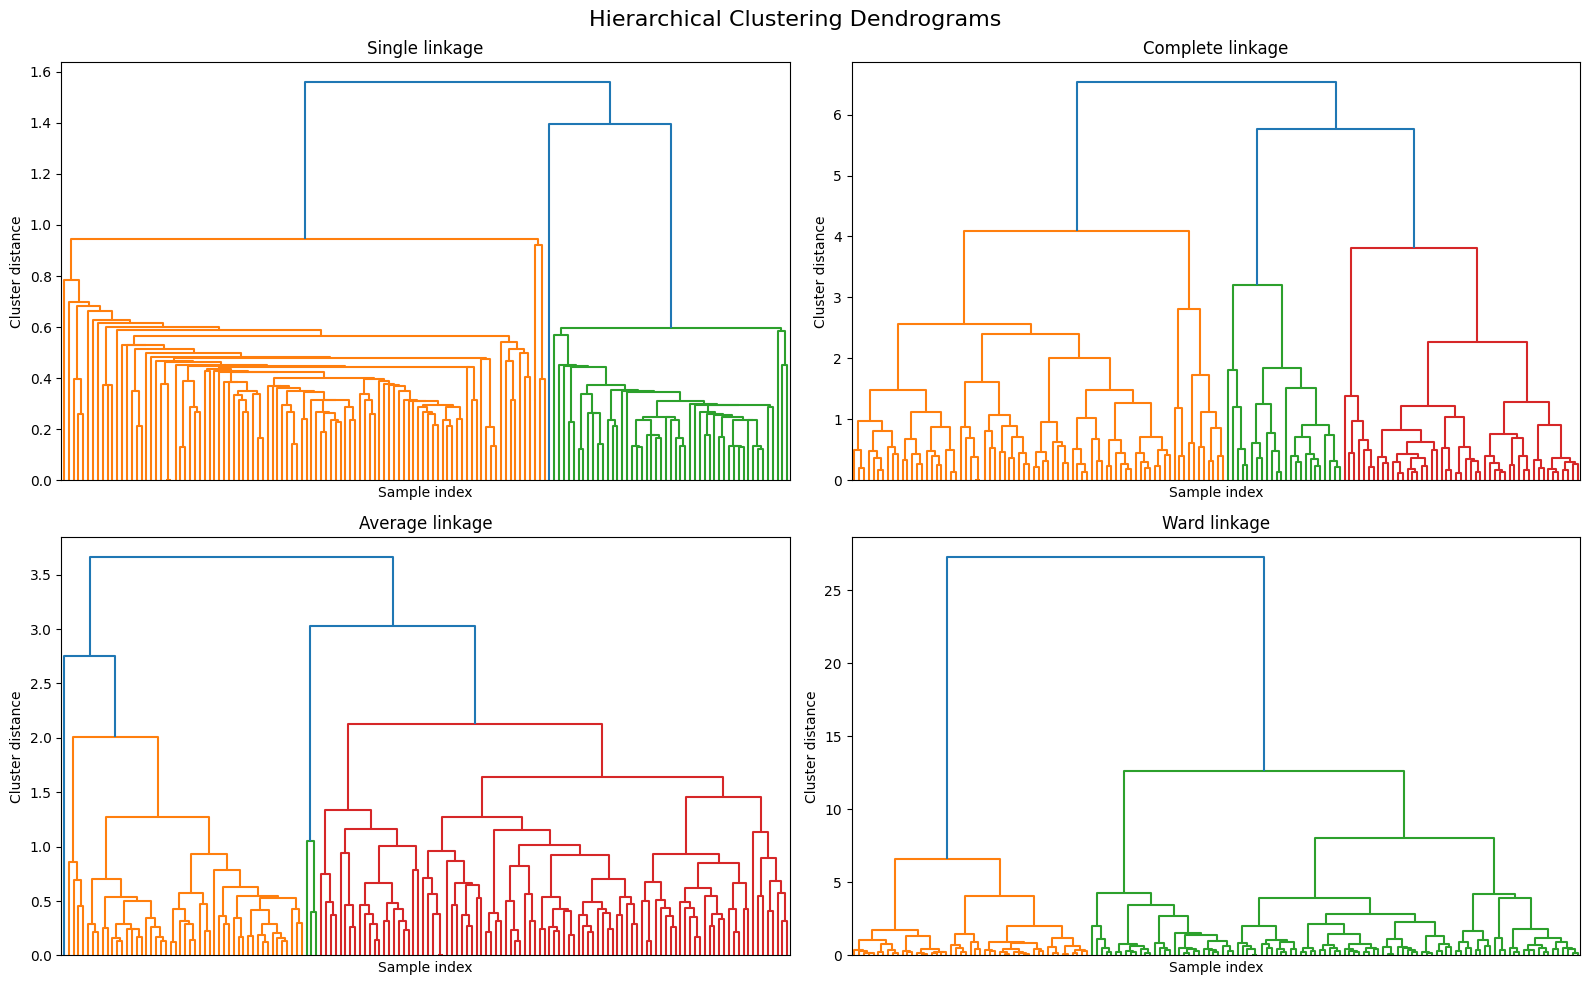

In [8]:
# Construct dendrograms from the linkage matrices.
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for axis, method in zip(axes.ravel(), linkage_methods):
    linkage_matrix = linkage(X_scaled, method=method)
    dendrogram(linkage_matrix, ax=axis, no_labels=True, color_threshold=None)
    axis.set_title(f"{method.title()} linkage")
    axis.set_xlabel("Sample index")
    axis.set_ylabel("Cluster distance")

fig.suptitle("Hierarchical Clustering Dendrograms", fontsize=16)
plt.tight_layout()
plt.show()